# Итоговый проект: Letter Classifier (EMNIST Letters)
## Цель
Разработать систему распознавания рукописных букв английского алфавита на основе датасета EMNIST Letters. Реализовать полный цикл создания модели машинного обучения — от загрузки данных до инференса на пользовательских примерах. В ходе выполнения проекта закрепить навыки работы с двумя основными фреймворками глубокого обучения — PyTorch и TensorFlow — и научиться сравнивать их между собой.

In [1]:
! pip install torch torchvision tensorflow matplotlib numpy scikit-learn pillow

In [2]:
# Импорт необходимых библиотек

import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout

import numpy as np
import pandas as pd
import time
import collections
import matplotlib.pyplot as plt
import seaborn as sns
import string
import random
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
import os

import seaborn as sns
from PIL import Image
from typing import Literal, Tuple, Any

In [3]:
# Фиксация случайности для воспроизводимости и выбор устройства (CPU/GPU)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# выбираем устройство
if torch.cuda.is_available():
    device = torch.device('cuda')
else:
    device = torch.device('cpu')

print(f"Используем устройство: {device}")

tf.random.set_seed(SEED)
os.environ['TF_DETERMINISTIC_OPS'] = '1'



Используем устройство: cuda


## Загрузка и подготовка данных
1. Загрузка датасета в PyTorch — через torchvision.

In [4]:
# определяем преобразования для изображений
transform = transforms.Compose([
    transforms.ToTensor(),                           # PIL → тензор, значения [0, 1]
    transforms.Lambda(lambda x: x.view(-1))          # (1,28,28) → (784)
])


# загрузка обучающей выборки
full_train_torch = datasets.EMNIST(
    root='./data',           # папка для сохранения данных
    split='letters',         # буквенный датасет (не digits или balanced)
    train=True,              # обучающая выборка
    download=True,           # скачать, если нет локально
    transform=transform      # применяем преобразования
)


# загрузка тестовой выборки
test_dataset_torch = datasets.EMNIST(
    root='./data',
    split='letters',
    train=False,             # тестовая выборка
    download=True,
    transform=transform
)


print(f"Размер полной обучающей выборки: {len(full_train_torch)}")
print(f"Размер оригинальной тестовой выборки: {len(test_dataset_torch)}")

100%|██████████| 562M/562M [00:04<00:00, 124MB/s] 


Размер полной обучающей выборки: 124800
Размер оригинальной тестовой выборки: 20800


2. Загрузка датасета в TensorFlow — через конвертацию из PyTorch.

In [5]:
# получение данных из PyTorch
X_train = full_train_torch.data.numpy().reshape(-1, 784).astype('float32') / 255.0
y_train = full_train_torch.targets.numpy().astype('int32') - 1


X_test = test_dataset_torch.data.numpy().reshape(-1, 784).astype('float32') / 255.0
y_test = test_dataset_torch.targets.numpy().astype('int32') - 1


print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_test: {X_test.shape}, y_test: {y_test.shape}")

X_train: (124800, 784), y_train: (124800,)
X_test: (20800, 784), y_test: (20800,)


## Исследовательский анализ данных
1. Общая информация

    1.1. Количество изображений в обучающей выборке

In [6]:
print(f"Количество изображений в обучающей выборке: {len(full_train_torch)} шт.")

Количество изображений в обучающей выборке: 124800 шт.


    1.2. Количество изображений в тестовой выборке

In [7]:
print(f"Количество изображений в тестовой выборке: {len(test_dataset_torch)} шт.")

Количество изображений в тестовой выборке: 20800 шт.


    1.3. Размер одного изображения в пикселях

In [8]:
first_image_tensor, _ = full_train_torch[0]
print(f"Размер изображения до преобразований: 28х28 пикселей")
print(f"Размер тензора после преобразований: {first_image_tensor.shape}")
print(f"Количество пикселей в одном векторе: {first_image_tensor.size(0)}")

Размер изображения до преобразований: 28х28 пикселей
Размер тензора после преобразований: torch.Size([784])
Количество пикселей в одном векторе: 784


    1.4. Диапазон значений пикселей (минимальное и максимальное значение).

In [9]:
print(f"Исходный диапазон пикселей всего датасета: от {full_train_torch.data.min()} до {full_train_torch.data.max()}")

min_val = first_image_tensor.min().item()
max_val = first_image_tensor.max().item()

print(f"Минимальное значение пикселя после преобразований: {min_val}")
print(f"Максимальное значение пикселя после преобразований: {max_val}")


Исходный диапазон пикселей всего датасета: от 0 до 255
Минимальное значение пикселя после преобразований: 0.0
Максимальное значение пикселя после преобразований: 1.0


2. Гистограмма распределения классов



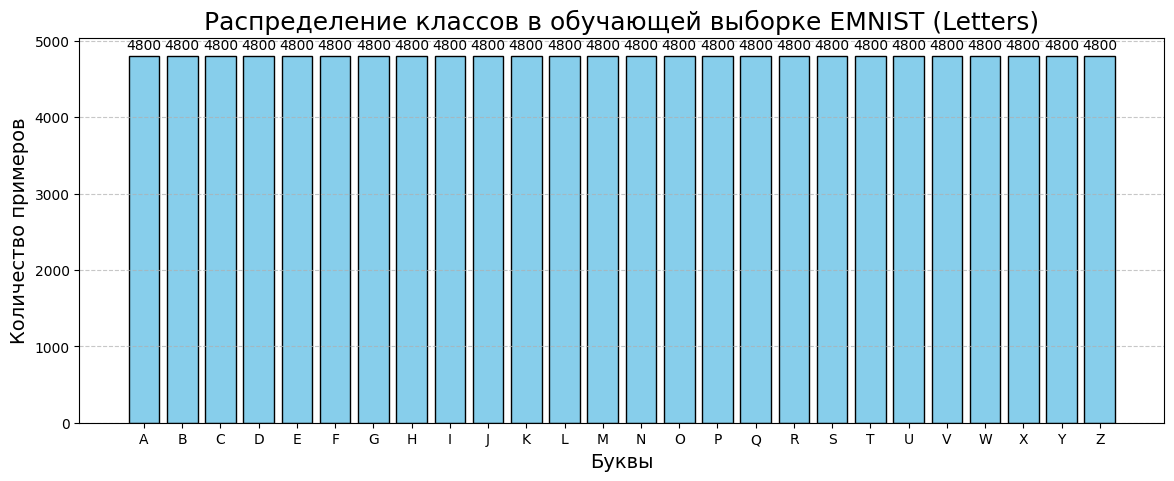

In [10]:
# Извлекаем все метки (targets) из обучающего датасета
labels = full_train_torch.targets.numpy()

# Подсчитываем количество элементов для каждого класса
counts = collections.Counter(labels)

alphabet = list(string.ascii_uppercase)
frequencies = [counts[i] for i in range(1, 27)]

# Строим гистограмму
plt.figure(figsize=(14, 5))
bars = plt.bar(alphabet, frequencies, color='skyblue', edgecolor='black')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 50, f'{yval}', ha='center', va='bottom', fontsize=10)

plt.title("Распределение классов в обучающей выборке EMNIST (Letters)", fontsize=18)
plt.xlabel("Буквы", fontsize=14)
plt.ylabel("Количество примеров", fontsize=14)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

Вывод: датасет сбалансирован. Для каждой буквы - 4 800 примеров.

3. Примеры изображений

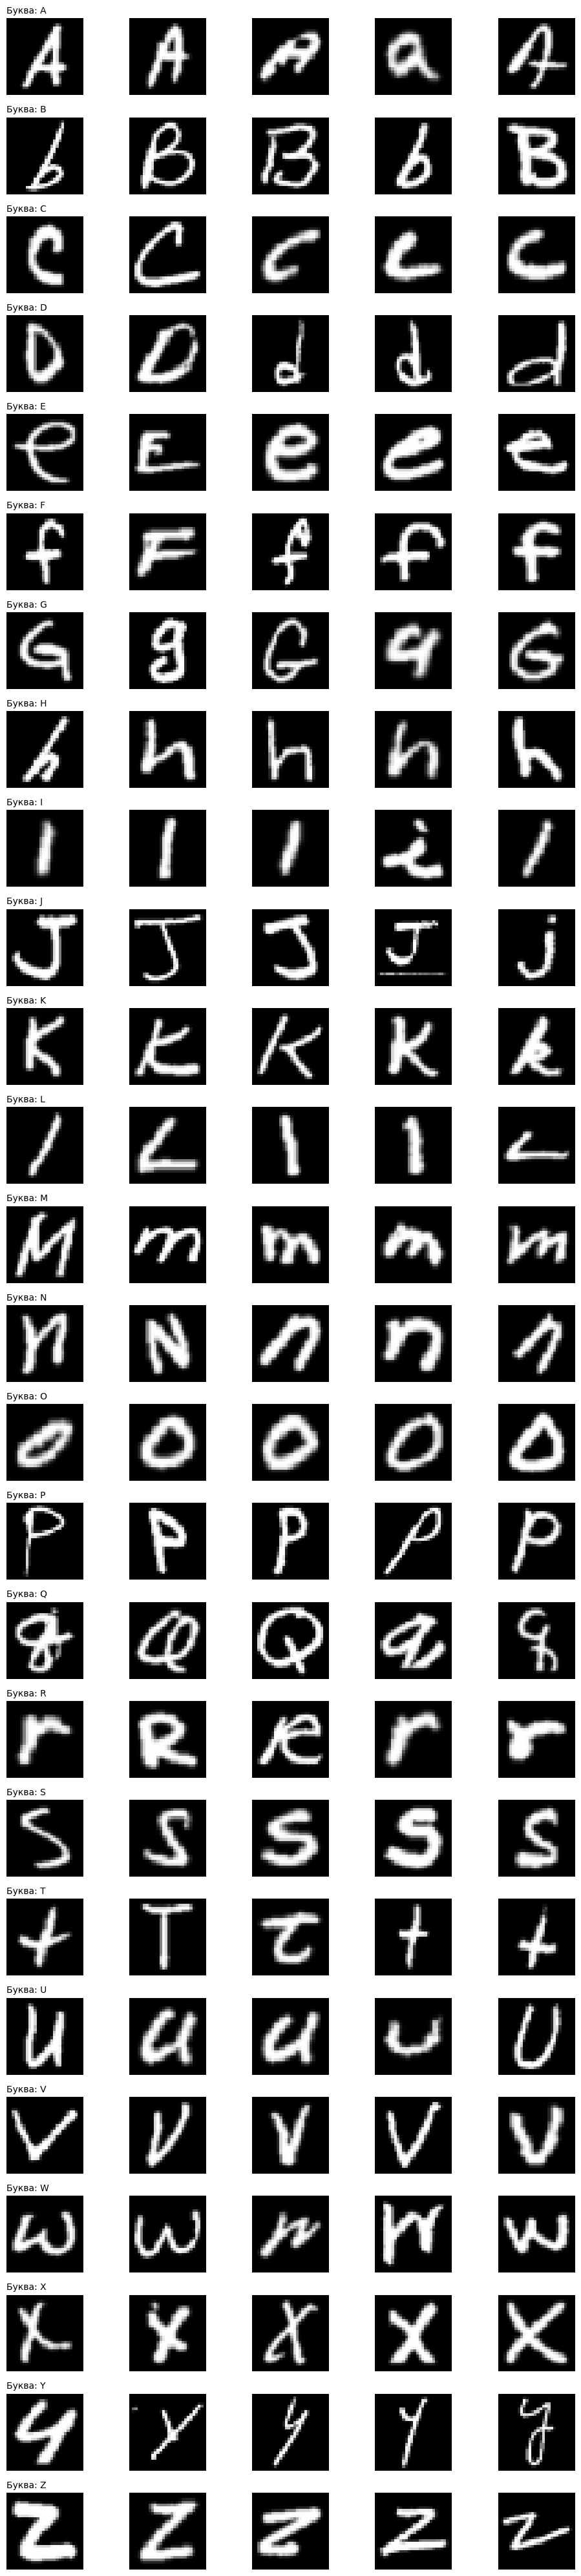

In [11]:
# Настраиваем сетку Matplotlib: 26 строк (классы), 5 столбцов (примеры)
fig, axes = plt.subplots(nrows=26, ncols=5, figsize=(10, 40))

rng = np.random.default_rng()

# Перебираем каждый класс от 1 до 26
for target_class in range(1, 27):
    letter = alphabet[target_class - 1]

    # Находим все индексы, где встречается текущая буква
    class_indices = np.where(labels == target_class)[0]

    # Выбираем 5 случайных индексов без повторений
    random_indices = rng.choice(class_indices, size=5, replace=False)

    for col_idx, img_idx in enumerate(random_indices):
        # Извлекаем тензор изображения и целевую метку
        img_tensor, _ = full_train_torch[img_idx]

        # 4. Восстанавливаем размер 28x28 и транспонируем (.t()),
        # чтобы исправить поворот картинок в EMNIST
        img_matrix = img_tensor.view(28, 28).t()

        # Получаем текущую ячейку на сетке графиков
        ax = axes[target_class - 1, col_idx]

        # Отображаем картинку
        ax.imshow(img_matrix, cmap='gray')
        ax.axis('off')

        # Подписываем букву только для первого столбца, чтобы не перегружать график
        if col_idx == 0:
            ax.set_title(f"Буква: {letter}", fontsize=10, loc='left')

# Настраиваем расположение, чтобы картинки не накладывались друг на друга
plt.tight_layout()
plt.show()

In [12]:
print("\n--- Проверка условий для всего обучающего датасета ---")

# Проверим, что значения лежат строго в рамках [0, 1]
all_correct = True
for i in range(len(full_train_torch)):
    img, _ = full_train_torch[i]
    if img.min() < 0.0 or img.max() > 1.0:
        all_correct = False
        break

if all_correct:
    print("Успешно: Все проверенные изображения находятся в диапазоне [0, 1]")
else:
    print("Ошибка: Обнаружены значения вне диапазона [0, 1]")

# Рандомно выбираем индекс от 0 до конца датасета
sample_index = random.randint(0, len(full_train_torch) - 1)
image_tensor, _ = full_train_torch[sample_index]

# 2. Находим минимальное и максимальное значения для этого изображения
min_val = image_tensor.min().item()
max_val = image_tensor.max().item()

print("--- Проверка одного случайного изображения ---")
print(f"Случайный индекс изображения: {sample_index}")
print(f"Минимальное значение пикселя: {min_val:.4f}")
print(f"Максимальное значение пикселя: {max_val:.4f}")


--- Проверка условий для всего обучающего датасета ---
Успешно: Все проверенные изображения находятся в диапазоне [0, 1]
--- Проверка одного случайного изображения ---
Случайный индекс изображения: 83810
Минимальное значение пикселя: 0.0000
Максимальное значение пикселя: 1.0000


## Разбиение на train и validation

In [13]:
# PyTorch

# Создаем генератор и устанавливаем для него seed
generator = torch.Generator().manual_seed(SEED)

# Расчитываем размеры выборок (90% и 10%)
train_size = int(0.9 * len(full_train_torch))
val_size = len(full_train_torch) - train_size

# Разделяем датасет
train_dataset_torch, val_dataset_torch = random_split(
    full_train_torch,
    [train_size, val_size],
    generator=generator
)

print(f"Размер обучающей выборки (90%): {len(train_dataset_torch)}")
print(f"Размер валидационной выборки (10%): {len(val_dataset_torch)}")

train_dataset_torch_loader = DataLoader(
    train_dataset_torch,
    batch_size=64,
    shuffle=True,
    num_workers=2
)

for images, labels in train_dataset_torch_loader:
    print(images.shape)  # torch.Size([64, 1, 28, 28])
    print(labels.shape)  # torch.Size([64])
    break

val_dataset_torch_loader = DataLoader(
    val_dataset_torch,
    batch_size=64,
    shuffle=True,
    num_workers=2
)

for images, labels in val_dataset_torch_loader:
    print(images.shape)  # torch.Size([64, 1, 28, 28])
    print(labels.shape)  # torch.Size([64])
    break

test_dataset_torch_loader = DataLoader(
    test_dataset_torch,
    batch_size=64,
    shuffle=True,
    num_workers=2
)

for images, labels in test_dataset_torch_loader:
    print(images.shape)  # torch.Size([64, 1, 28, 28])
    print(labels.shape)  # torch.Size([64])
    break

Размер обучающей выборки (90%): 112320
Размер валидационной выборки (10%): 12480
torch.Size([64, 784])
torch.Size([64])
torch.Size([64, 784])
torch.Size([64])
torch.Size([64, 784])
torch.Size([64])


In [14]:
# TensorFlow

# Разделяем NumPy-массивы на train и val (90% и 10%)
# Используем stratify=y_train, это гарантирует, что в обеих выборках
# будет одинаковый баланс букв, а random_state заменяет seed для воспроизводимости.
X_train_split, X_val_split, y_train_split, y_val_split = train_test_split(
    X_train,
    y_train,
    test_size=0.10,
    random_state=SEED,
    stratify=y_train
)

# Создаем tf.data.Dataset для Обучающей выборки
BATCH_SIZE = 64
train_dataset_tflow = tf.data.Dataset.from_tensor_slices((X_train_split, y_train_split))
train_dataset_tflow = (train_dataset_tflow

                       .shuffle(10000)
                       .batch(BATCH_SIZE)
                       .prefetch(tf.data.AUTOTUNE))

# Создаем tf.data.Dataset для Валидационной выборки
val_dataset_tflow = tf.data.Dataset.from_tensor_slices((X_val_split, y_val_split))
val_dataset_tflow = (val_dataset_tflow

                     .batch(BATCH_SIZE)
                     .prefetch(tf.data.AUTOTUNE))

# Создаем tf.data.Dataset для Тестовой выборки (ваш оригинальный код)
test_dataset_tflow = tf.data.Dataset.from_tensor_slices((X_test, y_test))
test_dataset_tflow = (test_dataset_tflow

                      .batch(BATCH_SIZE)
                      .prefetch(tf.data.AUTOTUNE))

В рамках учебной задачи PyTorch объективно удобнее и интуитивно понятнее. Благодаря синтаксису, похожему на Python, и встроенным методам, данные легко контролировать. Можно в любой момент обратиться к конкретному элементу датасета как к обычному списку, проверить его форму или диапазон пикселей.TensorFlow требует гораздо больше «телодвижений» и написания кода. Приходится вручную переводить данные в NumPy-массивы, делить их сторонними библиотеками и т.д., что скорее усложняет процесс подготовки данных.

## Baseline MLP-модели

In [15]:
class MLP(nn.Module):
    def __init__(self, dropout=True):
        super(MLP, self).__init__()  # вызываем конструктор родителя
        # Объявление слоев
        self.fc1 = nn.Linear(784, 512)
        self.fc2 = nn.Linear(512, 256)
        self.fc3 = nn.Linear(256, 128)
        self.fc4 = nn.Linear(128, 26)

        # Функция активации
        self.relu = nn.ReLU()

        # Дропаут
        self.dropout = nn.Dropout(0.3) if dropout else nn.Identity()

        # Softmax не добавляется в forward, так как nn.CrossEntropyLoss принимает сырые логиты

    def forward(self, x):
        # здесь описывается прямой проход
        x = self.dropout(self.relu(self.fc1(x)))
        x = self.dropout(self.relu(self.fc2(x)))
        x = self.dropout(self.relu(self.fc3(x)))
        x = self.fc4(x)
        return x

In [16]:
def train_and_evaluate(model, train_loader, val_loader, test_loader, epochs=10, lr=0.001, save_path="mlp_model.pth"):
    # Перенос модели на GPU при наличии
    model = model.to(device)

    # Функция потерь и оптимизатор
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    # Запись значений потерь, метрики, времени
    torch_loss_history = []
    torch_val_acc_history = []
    epoch_times = []

    # Цикл обучения
    for epoch in range(epochs):
        model.train()
        running_loss = 0.0

        # Начинаем отсчет времени
        if device.type == 'cuda':
            torch.cuda.synchronize()
        start_time = time.time()

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            # Сдвигаем метки из диапазона [1, 26] в диапазон [0, 25]
            labels = labels - 1

            # Обнуление градиентов
            optimizer.zero_grad()

            # Прямой проход и расчет потерь
            outputs = model(images)
            loss = criterion(outputs, labels)

            # Обратный проход и шаг оптимизации
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)

        if device.type == 'cuda':
            torch.cuda.synchronize()
        end_time = time.time() # Стоп замера времени эпохи

        epoch_duration = end_time - start_time
        epoch_times.append(epoch_duration)

        epoch_loss = running_loss / len(train_loader.dataset)

        # Валидация после каждой эпохи
        model.eval()
        correct = 0
        total = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)

                # Сдвигаем метки для валидации
                labels = labels - 1

                outputs = model(images)
                _, predicted = torch.max(outputs.data, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        val_accuracy = 100 * correct / total

        torch_loss_history.append(epoch_loss)
        torch_val_acc_history.append(val_accuracy)

        print(f"Эпоха [{epoch+1}/{epochs}] | Loss: {epoch_loss:.4f} | Валидационная Accuracy: {val_accuracy:.2f}%")

    # Тестирование после завершения обучения
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)

            # Сдвигаем метки для теста
            labels = labels - 1

            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    test_accuracy = 100 * correct / total
    print(f"\nИтоговая Accuracy на тестовой выборке: {test_accuracy:.2f}%")

    torch_avg_epoch_time = sum(epoch_times) / len(epoch_times)
    print(f"Среднее время обучения одной эпохи: {torch_avg_epoch_time:.3f} сек")

    # Сохранение модели
    torch.save(model.state_dict(), save_path)
    print(f"Модель успешно сохранена в файл: {save_path}")

    return torch_loss_history, torch_val_acc_history, torch_avg_epoch_time, test_accuracy


In [17]:
model_torch= MLP(dropout=False)

# Вызов функции обучения
torch_loss_history, torch_val_acc_history, torch_avg_epoch_time, torch_test_accuracy = train_and_evaluate(
    model=model_torch,
    train_loader=train_dataset_torch_loader,
    val_loader=val_dataset_torch_loader,
    test_loader=test_dataset_torch_loader,
    epochs=10,
    lr=0.001,
    save_path="model_torch.pth"
)



Эпоха [1/10] | Loss: 0.6570 | Валидационная Accuracy: 87.14%
Эпоха [2/10] | Loss: 0.3219 | Валидационная Accuracy: 89.54%
Эпоха [3/10] | Loss: 0.2567 | Валидационная Accuracy: 90.58%
Эпоха [4/10] | Loss: 0.2188 | Валидационная Accuracy: 90.89%
Эпоха [5/10] | Loss: 0.1927 | Валидационная Accuracy: 91.16%
Эпоха [6/10] | Loss: 0.1729 | Валидационная Accuracy: 91.37%
Эпоха [7/10] | Loss: 0.1565 | Валидационная Accuracy: 91.59%
Эпоха [8/10] | Loss: 0.1428 | Валидационная Accuracy: 91.88%
Эпоха [9/10] | Loss: 0.1320 | Валидационная Accuracy: 91.36%
Эпоха [10/10] | Loss: 0.1248 | Валидационная Accuracy: 91.50%

Итоговая Accuracy на тестовой выборке: 91.23%
Среднее время обучения одной эпохи: 18.163 сек
Модель успешно сохранена в файл: model_torch.pth


In [18]:
# Класс для учета времени эпохи для TensorFlow
class TimeHistory(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.epoch_times = []

    def on_epoch_begin(self, epoch, logs=None):
        # Принудительно синхронизируем GPU (если обучение идет на видеокарте)
        tf.keras.backend.clear_session()
        self.epoch_start_time = time.time()

    def on_epoch_end(self, epoch, logs=None):
        epoch_time = time.time() - self.epoch_start_time
        self.epoch_times.append(epoch_time)
        # Выводим время эпохи прямо в лог обучения
        print(f" — Время эпохи: {epoch_time:.2f} сек")

In [19]:
# Конструктор модели
initializer = tf.keras.initializers.VarianceScaling(
    scale=1.0,
    mode='fan_in',
    distribution='uniform',
    seed=SEED
)

model_tflow = Sequential([
    Input(shape=(784,)),             # Входной слой (784)
    Dense(512, activation='relu', kernel_initializer=initializer),   # Слой 1: 512 нейронов, ReLU
    Dense(256, activation='relu', kernel_initializer=initializer),   # Слой 2: 256 нейронов, ReLU
    Dense(128, activation='relu', kernel_initializer=initializer),   # Слой 3: 128 нейронов, ReLU
    Dense(26, activation='softmax', kernel_initializer=initializer)  # Выходной слой: 26 нейронов, Softmax
])

model_tflow.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

time_callback = TimeHistory()

# Обучение модели на подготовленных tf.data.Dataset
history = model_tflow.fit(
    train_dataset_tflow,
    epochs=10,
    validation_data=val_dataset_tflow,
    callbacks=[time_callback]
)

tflow_epoch_times = time_callback.epoch_times
tflow_avg_time = sum(tflow_epoch_times) / len(tflow_epoch_times)

# Вычисление accuracy на тестовой выборке
test_loss, test_acc = model_tflow.evaluate(test_dataset_tflow, verbose=0)
print(f"\nИтоговая Accuracy на тестовой выборке: {test_acc * 100:.2f}%")

print(f"\n[TF] Время по эпохам: {[round(t, 2) for t in tflow_epoch_times]} сек")
print(f"[TF] Среднее время обучения одной эпохи: {tflow_avg_time:.3f} сек")

# Сохранение модели
save_path_tf = "mlp_model_tflow.h5"
model_tflow.save(save_path_tf)
print(f"Модель успешно сохранена в файл: {save_path_tf}")

Epoch 1/10
1755/1755 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7192 - loss: 0.9409 — Время эпохи: 14.40 сек
1755/1755 ━━━━━━━━━━━━━━━━━━━━ 14s 6ms/step - accuracy: 0.8150 - loss: 0.5968 - val_accuracy: 0.8825 - val_loss: 0.3593
Epoch 2/10
1754/1755 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8915 - loss: 0.3295 — Время эпохи: 11.72 сек
1755/1755 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.8965 - loss: 0.3114 - val_accuracy: 0.8938 - val_loss: 0.3281
Epoch 3/10
1747/1755 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9115 - loss: 0.2629 — Время эпохи: 10.50 сек
1755/1755 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9137 - loss: 0.2526 - val_accuracy: 0.9067 - val_loss: 0.2955
Epoch 4/10
1749/1755 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9251 - loss: 0.2176 — Время эпохи: 10.50 сек
1755/1755 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9263 - loss: 0.2138 - val_accuracy: 0.9040 - val_loss: 0.2984
Epoch 5/10
1750/1755 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.


Итоговая Accuracy на тестовой выборке: 90.76%

[TF] Время по эпохам: [14.4, 11.72, 10.5, 10.5, 10.53, 9.75, 10.18, 10.64, 10.5, 10.57] сек
[TF] Среднее время обучения одной эпохи: 10.929 сек
Модель успешно сохранена в файл: mlp_model_tflow.h5


In [20]:
# Определение количества параметров
tflow_loss = history.history['loss']
tflow_val_acc = [acc * 100 for acc in history.history['val_accuracy']] # Переводим в проценты

tflow_params = model_tflow.count_params()
print(f"Параметров в TensorFlow: {tflow_params:,}")

torch_params = sum(p.numel() for p in model_torch.parameters() if p.requires_grad)
print(f"Параметров в PyTorch: {torch_params:,}")


Параметров в TensorFlow: 569,498
Параметров в PyTorch: 569,498


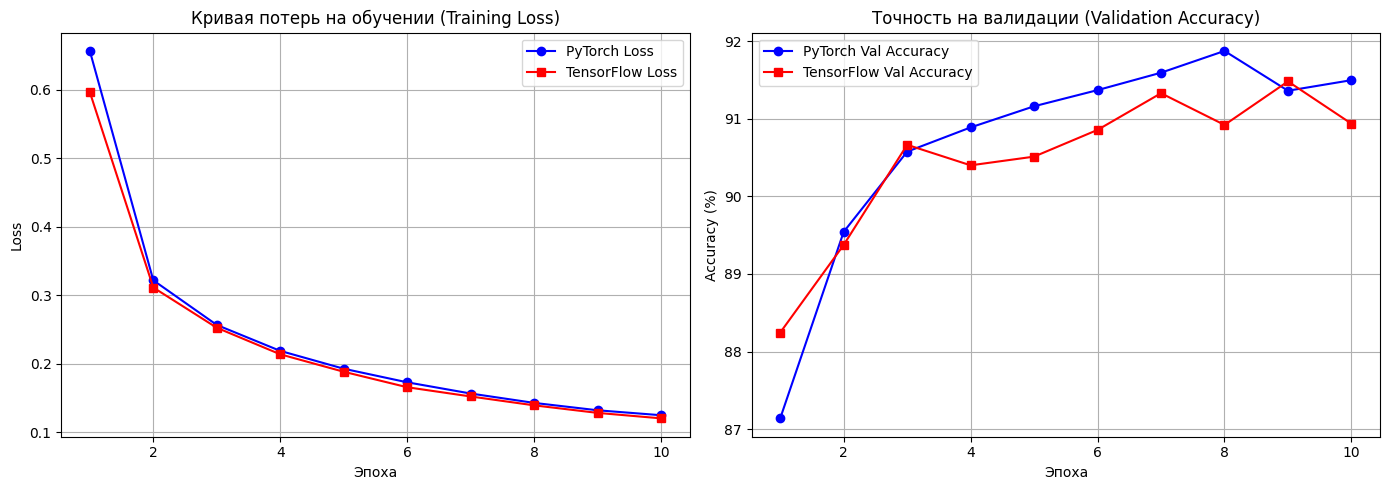

In [21]:
# Построение графиков
epochs_range = range(1, 11)

plt.figure(figsize=(14, 5))

# График 1: Loss на обучении
plt.subplot(1, 2, 1)
plt.plot(epochs_range, torch_loss_history, 'b-o', label='PyTorch Loss')
plt.plot(epochs_range, tflow_loss, 'r-s', label='TensorFlow Loss')
plt.title('Кривая потерь на обучении (Training Loss)')
plt.xlabel('Эпоха')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()

# График 2: Validation Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs_range, torch_val_acc_history, 'b-o', label='PyTorch Val Accuracy')
plt.plot(epochs_range, tflow_val_acc, 'r-s', label='TensorFlow Val Accuracy')
plt.title('Точность на валидации (Validation Accuracy)')
plt.xlabel('Эпоха')
plt.ylabel('Accuracy (%)')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

In [22]:
tflow_test_accuracy_pct = test_acc * 100 if test_acc <= 1.0 else test_acc
metrics_data = {
    "PyTorch": [torch_params, torch_avg_epoch_time, torch_test_accuracy],
    "TensorFlow": [tflow_params, tflow_avg_time, tflow_test_accuracy_pct]
}

# Создаем таблицу
df = pd.DataFrame(metrics_data, index=["Параметры", "Время эпохи (сек)", "Test Accuracy (%)"])

# Форматирование и округление до 2 знаков
df_styled = df.style.format({
    "PyTorch": lambda x: f"{int(x)}" if x == torch_params else f"{x:.2f}",
    "TensorFlow": lambda x: f"{int(x)}" if x == tflow_params else f"{x:.2f}"
})

# Отображаем отформатированную таблицу
df_styled

,PyTorch,TensorFlow
Параметры,569498,569498
Время эпохи (сек),18.16,10.93
Test Accuracy (%),91.23,90.76


Вывод:

PyTorch показал более высокий результат метрики на тестовой выборке против TensorFlow.

На графике валидации заметно, что PyTorch стабильнее удерживал точность на последних эпохах, в то время как у TensorFlow на последних эпохах началось легкое переобучение (loss падал, но val_accuracy снизилась).

TensorFlow оказался гораздо быстрее, затрачивая в среднем около 10 секунд на эпоху, что примерно в 2 раза быстрее результата PyTorch (около 18 сек).

Причина скорее всего связана с использованием tf.data.Dataset и метода .prefetch(tf.data.AUTOTUNE). TensorFlow эффективно задействовал многопоточность процессора для подготовки следующих батчей во время работы GPU. В PyTorch использовался стандартный цикл, который тратил время на передачу данных между CPU и GPU на каждой итерации.

TensorFlow (Keras) также оказался значительно удобнее. Конструкция Sequential и метод .fit() берут на себя автоматический расчет метрик, валидацию и вывод прогресс-бара.

PyTorch требует ручного написания циклов обучения.

## Улучшение модели с помощью Dropout

In [23]:
# PyTorch

model_torch_dropout= MLP(dropout=True)

# Вызов функции обучения
torch_dropout_loss_history, torch_dropout_val_acc_history, torch_dropout_avg_epoch_time, torch_dropout_test_accuracy = train_and_evaluate(
    model=model_torch_dropout,
    train_loader=train_dataset_torch_loader,
    val_loader=val_dataset_torch_loader,
    test_loader=test_dataset_torch_loader,
    epochs=10,
    lr=0.001,
    save_path="model_torch_dropout.pth"
)


Эпоха [1/10] | Loss: 0.9043 | Валидационная Accuracy: 86.58%
Эпоха [2/10] | Loss: 0.5100 | Валидационная Accuracy: 88.88%
Эпоха [3/10] | Loss: 0.4362 | Валидационная Accuracy: 90.10%
Эпоха [4/10] | Loss: 0.3991 | Валидационная Accuracy: 90.87%
Эпоха [5/10] | Loss: 0.3769 | Валидационная Accuracy: 91.21%
Эпоха [6/10] | Loss: 0.3592 | Валидационная Accuracy: 91.23%
Эпоха [7/10] | Loss: 0.3406 | Валидационная Accuracy: 91.57%
Эпоха [8/10] | Loss: 0.3271 | Валидационная Accuracy: 91.37%
Эпоха [9/10] | Loss: 0.3254 | Валидационная Accuracy: 91.85%
Эпоха [10/10] | Loss: 0.3160 | Валидационная Accuracy: 91.59%

Итоговая Accuracy на тестовой выборке: 91.44%
Среднее время обучения одной эпохи: 18.193 сек
Модель успешно сохранена в файл: model_torch_dropout.pth


In [24]:
# TensorFlow

# Конструктор модели
model_tflow_dropout = Sequential([
    Input(shape=(784,)),

    Dense(512, activation='relu', kernel_initializer=initializer),
    Dropout(0.3),                       # Добавили Dropout после 1-го слоя

    Dense(256, activation='relu', kernel_initializer=initializer),
    Dropout(0.3),                       # Добавили Dropout после 2-го слоя

    Dense(128, activation='relu', kernel_initializer=initializer),
    Dropout(0.3),                       # Добавили Dropout после 3-го слоя

    Dense(26, activation='softmax', kernel_initializer=initializer)
])

model_tflow_dropout.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

time_callback_drop = TimeHistory()

# Обучение модели на подготовленных tf.data.Dataset
history_dropout = model_tflow_dropout.fit(
    train_dataset_tflow,
    epochs=10,
    validation_data=val_dataset_tflow,
    callbacks=[time_callback_drop]
)

test_loss_drop, test_acc_drop = model_tflow_dropout.evaluate(test_dataset_tflow, verbose=0)
tflow_acc_drop_percentage = test_acc_drop * 100 if test_acc_drop <= 1.0 else test_acc_drop

tflow_avg_time_drop = sum(time_callback_drop.epoch_times) / len(time_callback_drop.epoch_times)

# Вычисление accuracy на тестовой выборке
print(f"\nИтоговая Accuracy TensorFlow с Dropout: {tflow_acc_drop_percentage:.2f}%")
print(f"Среднее время обучения эпохи: {tflow_avg_time_drop:.3f} сек")

# Сохранение модели
model_tflow_dropout.save("mlp_model_tflow_dropout.h5")


Epoch 1/10
1752/1755 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6023 - loss: 1.3236 — Время эпохи: 13.82 сек
1755/1755 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - accuracy: 0.7281 - loss: 0.8926 - val_accuracy: 0.8702 - val_loss: 0.4159
Epoch 2/10
1750/1755 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8326 - loss: 0.5397 — Время эпохи: 11.89 сек
1755/1755 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.8407 - loss: 0.5148 - val_accuracy: 0.8783 - val_loss: 0.3735
Epoch 3/10
1754/1755 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8582 - loss: 0.4503 — Время эпохи: 12.03 сек
1755/1755 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.8625 - loss: 0.4397 - val_accuracy: 0.8982 - val_loss: 0.3278
Epoch 4/10
1751/1755 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8716 - loss: 0.4040 — Время эпохи: 11.72 сек
1755/1755 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.8730 - loss: 0.3994 - val_accuracy: 0.9033 - val_loss: 0.3020
Epoch 5/10
1752/1755 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.


Итоговая Accuracy TensorFlow с Dropout: 91.30%
Среднее время обучения эпохи: 12.063 сек


In [25]:
tflow_dropout_loss = history_dropout.history['loss']
tflow_dropout_val_acc = [acc * 100 for acc in history_dropout.history['val_accuracy']] # Переводим в проценты

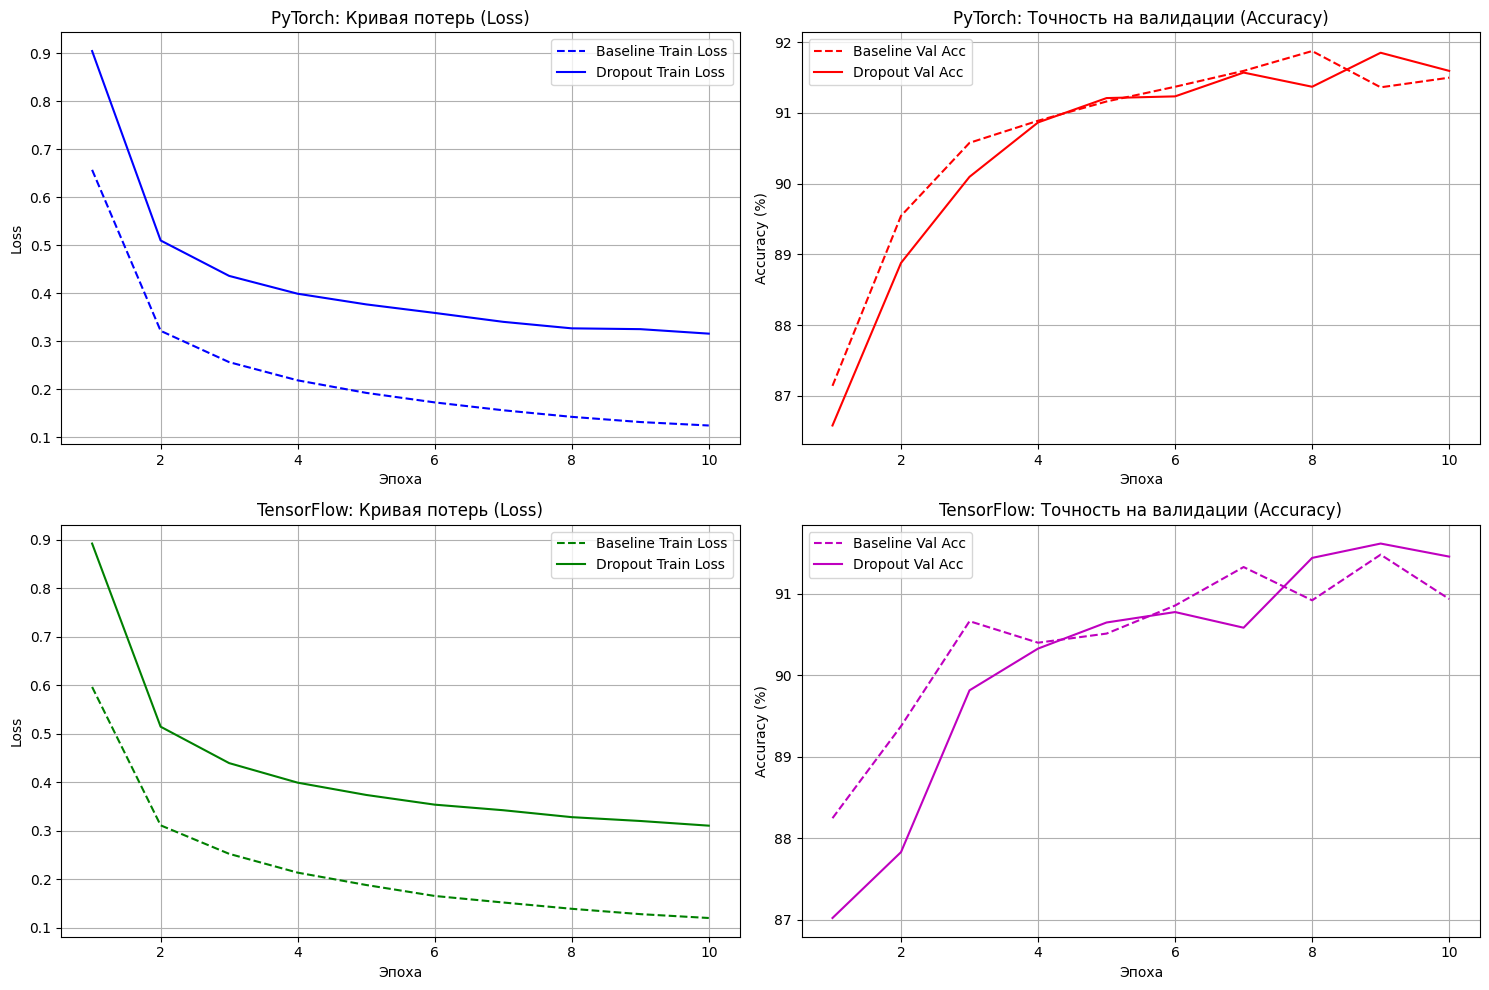

In [26]:
epochs = range(1, 11)

# PyTorch метрики
pt_loss_base = torch_loss_history
pt_acc_base  = torch_val_acc_history
pt_loss_drop = torch_dropout_loss_history
pt_acc_drop  = torch_dropout_val_acc_history

# TensorFlow метрики
tf_loss_base = tflow_loss
tf_acc_base  = tflow_val_acc
tf_loss_drop = tflow_dropout_loss
tf_acc_drop  = tflow_dropout_val_acc

# Создаем общий рисунок 2х2
fig, axs = plt.subplots(2, 2, figsize=(15, 10))

# PyTorch
# Training Loss
axs[0, 0].plot(epochs, pt_loss_base, 'b--', label='Baseline Train Loss')
axs[0, 0].plot(epochs, pt_loss_drop, 'b-', label='Dropout Train Loss')
axs[0, 0].set_title('PyTorch: Кривая потерь (Loss)')
axs[0, 0].set_xlabel('Эпоха')
axs[0, 0].set_ylabel('Loss')
axs[0, 0].grid(True)
axs[0, 0].legend()

# Validation Accuracy
axs[0, 1].plot(epochs, pt_acc_base, 'r--', label='Baseline Val Acc')
axs[0, 1].plot(epochs, pt_acc_drop, 'r-', label='Dropout Val Acc')
axs[0, 1].set_title('PyTorch: Точность на валидации (Accuracy)')
axs[0, 1].set_xlabel('Эпоха')
axs[0, 1].set_ylabel('Accuracy (%)')
axs[0, 1].grid(True)
axs[0, 1].legend()

# TensorFlow
# Training Loss
axs[1, 0].plot(epochs, tf_loss_base, 'g--', label='Baseline Train Loss')
axs[1, 0].plot(epochs, tf_loss_drop, 'g-', label='Dropout Train Loss')
axs[1, 0].set_title('TensorFlow: Кривая потерь (Loss)')
axs[1, 0].set_xlabel('Эпоха')
axs[1, 0].set_ylabel('Loss')
axs[1, 0].grid(True)
axs[1, 0].legend()

# Validation Accuracy
axs[1, 1].plot(epochs, tf_acc_base, 'm--', label='Baseline Val Acc')
axs[1, 1].plot(epochs, tf_acc_drop, 'm-', label='Dropout Val Acc')
axs[1, 1].set_title('TensorFlow: Точность на валидации (Accuracy)')
axs[1, 1].set_xlabel('Эпоха')
axs[1, 1].set_ylabel('Accuracy (%)')
axs[1, 1].grid(True)
axs[1, 1].legend()

plt.tight_layout()
plt.show()


Вывод:

Да, добавление слоя Dropout помогло справиться с переобучением в обоих фреймворках.

У моделей с Dropout (сплошные линии) кривая потерь на обучении падает заметно медленнее и итоговый лосс к 10-й эпохе остается выше, чем у Baseline-моделей (пунктирные линии). Это говорит о том, что нейросеть перестала  «заучивать» обучающий датасет и подстраиваться под шум в данных.

У Baseline-моделей (пунктир) точность на валидации сначала повышается, затем выходит на плато, а к 9–10 эпохам начинает стагнировать и падать. Это классический симптом переобучения. Слой Dropout (сплошная линия) исправил эту ситуацию: точность стабильнее росла на протяжении всех 10 эпох и в итоге перешагнула пиковое значение Baseline-модели.



In [27]:
tflow_dropout_test_accuracy_pct = test_acc_drop * 100 if test_acc_drop <= 1.0 else test_acc_drop
metrics_data_final = {
    "PyTorch": [torch_test_accuracy],
    "TensorFlow": [tflow_test_accuracy_pct],
    "PyTorch_dropout": [torch_dropout_test_accuracy],
    "TensorFlow_dropout": [tflow_dropout_test_accuracy_pct]
}

# Создаем таблицу
df_final = pd.DataFrame(metrics_data_final, index=["Test Accuracy (%)"])

df_final_styled = df_final.style.format("{:.2f}%")

# Отображаем отформатированную таблицу
df_final_styled

,PyTorch,TensorFlow,PyTorch_dropout,TensorFlow_dropout
Test Accuracy (%),91.23%,90.76%,91.44%,91.30%


Лучшие метрики на тесте показали модели с Dropout на обоих фреймворках, они будут использованы для дальнейшей работы.

## Анализ ошибок

### Confusion matrix

In [28]:
# Создаем список букв от A до Z для подписей осей
labels_az = list(string.ascii_uppercase)

# Предсказания для PyTorch
model_torch_dropout.eval()

torch_preds = []
torch_trues = []

with torch.no_grad():
    for images, labels in test_dataset_torch_loader:
        images = images.to(device)
        outputs = model_torch_dropout(images)
        _, predicted = torch.max(outputs, 1)

        torch_preds.extend(predicted.cpu().numpy())
        corrected_labels = labels - 1
        torch_trues.extend(corrected_labels.numpy())

# Строим матрицу ошибок для PyTorch
cm_torch = confusion_matrix(torch_trues, torch_preds)

# Предсказания для TensorFlow

# Метод predict возвращает вероятности для каждого класса
tflow_probs = model_tflow_dropout.predict(test_dataset_tflow)
# Берем индекс класса с максимальной вероятностью
tflow_preds = np.argmax(tflow_probs, axis=1)

# Собираем реальные метки из tf.data.Dataset для проверки
tflow_trues = np.concatenate([y.numpy() for _, y in test_dataset_tflow], axis=0)

# Строим матрицу ошибок для TensorFlow
cm_tflow = confusion_matrix(tflow_trues, tflow_preds)

325/325 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


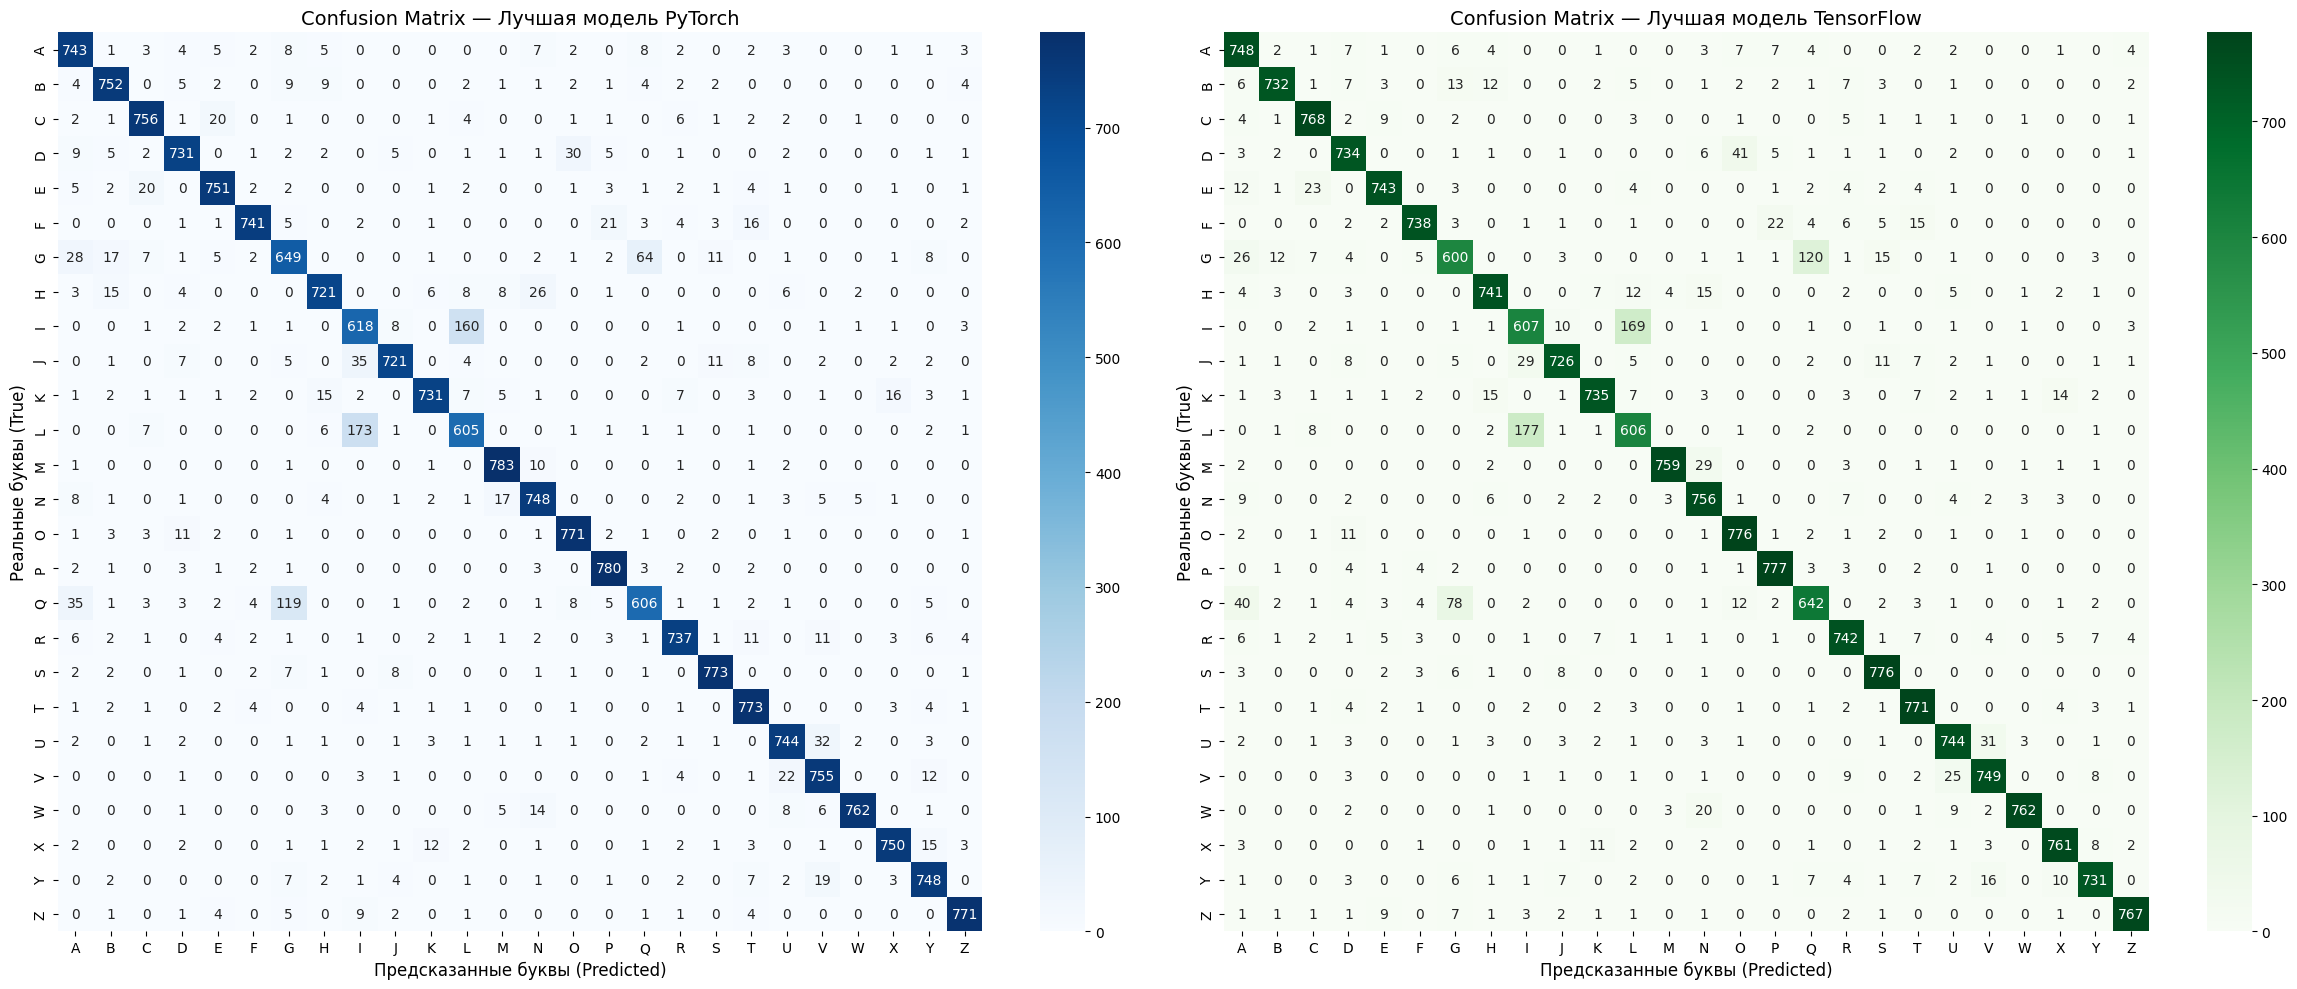

In [29]:
plt.figure(figsize=(24, 10))

# График 1: Матрица ошибок PyTorch
plt.subplot(1, 2, 1)
sns.heatmap(
    cm_torch,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels_az,
    yticklabels=labels_az
)
plt.title('Confusion Matrix — Лучшая модель PyTorch', fontsize=14)
plt.xlabel('Предсказанные буквы (Predicted)', fontsize=12)
plt.ylabel('Реальные буквы (True)', fontsize=12)

# График 2: Матрица ошибок TensorFlow
plt.subplot(1, 2, 2)
sns.heatmap(
    cm_tflow,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=labels_az,
    yticklabels=labels_az
)
plt.title('Confusion Matrix — Лучшая модель TensorFlow', fontsize=14)
plt.xlabel('Предсказанные буквы (Predicted)', fontsize=12)
plt.ylabel('Реальные буквы (True)', fontsize=12)

plt.tight_layout()
plt.show()

### Топ-5 пар ошибок

In [30]:
n_classes = len(labels_az)

# Переменные для удобного перебора в цикле
frameworks_data = {
    "PYTORCH": cm_torch,
    "TENSORFLOW": cm_tflow
}

for name, matrix in frameworks_data.items():
    print(f"               Анализ модели {name}                      ")


    # ТОП-5 лучших букв
    class_accuracies = []
    for i in range(n_classes):
        total_real = matrix[i, :].sum()
        correct_preds = matrix[i, i]
        acc = (correct_preds / total_real * 100) if total_real > 0 else 0
        class_accuracies.append((labels_az[i], acc, correct_preds, total_real))

    top5_best = sorted(class_accuracies, key=lambda x: x[1], reverse=True)[:5]

    print("ТОП-5 букв с лучшим распознаванием:")
    for rank, (letter, acc, correct, total) in enumerate(top5_best, 1):
        print(f"  {rank}. Буква '{letter}': Точность {acc:.2f}% ({correct} из {total} угадано правильно)")

    # ТОП-5 самых частых путаниц
    errors_list = []
    for i in range(n_classes):
        for j in range(n_classes):
            if i != j:
                error_count = matrix[i, j]
                if error_count > 0:
                    errors_list.append((labels_az[i], labels_az[j], error_count))

    top5_confused = sorted(errors_list, key=lambda x: x[2], reverse=True)[:5]

    print("\nТОП-5 самых частых путаниц:")
    for rank, (true_letter, pred_letter, count) in enumerate(top5_confused, 1):
        print(f"  {rank}. Реальную '{true_letter}' перепутали с '{pred_letter}': {count} раз")
    print("\n                                                                                  ")


               Анализ модели PYTORCH                      
ТОП-5 букв с лучшим распознаванием:
  1. Буква 'M': Точность 97.88% (783 из 800 угадано правильно)
  2. Буква 'P': Точность 97.50% (780 из 800 угадано правильно)
  3. Буква 'S': Точность 96.62% (773 из 800 угадано правильно)
  4. Буква 'T': Точность 96.62% (773 из 800 угадано правильно)
  5. Буква 'O': Точность 96.38% (771 из 800 угадано правильно)

ТОП-5 самых частых путаниц:
  1. Реальную 'L' перепутали с 'I': 173 раз
  2. Реальную 'I' перепутали с 'L': 160 раз
  3. Реальную 'Q' перепутали с 'G': 119 раз
  4. Реальную 'G' перепутали с 'Q': 64 раз
  5. Реальную 'J' перепутали с 'I': 35 раз

                                                                                  
               Анализ модели TENSORFLOW                      
ТОП-5 букв с лучшим распознаванием:
  1. Буква 'P': Точность 97.12% (777 из 800 угадано правильно)
  2. Буква 'O': Точность 97.00% (776 из 800 угадано правильно)
  3. Буква 'S': Точность 97.00% (77

### Визуализация примеров ошибок

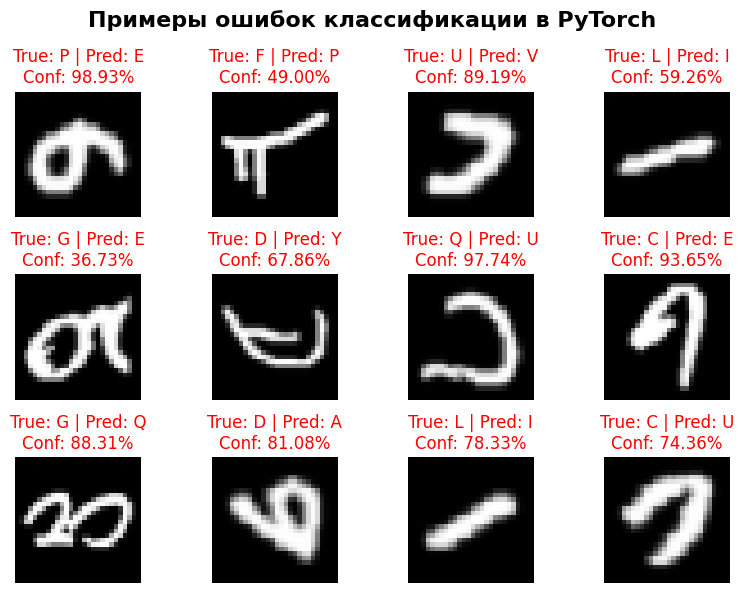

In [31]:
model_torch_dropout.eval()

error_images = []
error_trues = []
error_preds = []
error_confs = []

# Перебираем тестовый датасет, пока не наберем нужное количество ошибок
with torch.no_grad():
    for images, labels in test_dataset_torch_loader:
        images_dev = images.to(device)
        outputs = model_torch_dropout(images_dev)

        # Считаем вероятности (уверенность) через Softmax
        probabilities = F.softmax(outputs, dim=1)
        confs, predicted = torch.max(probabilities, 1)

        # Приводим реальные метки к диапазону [0, 25]
        corrected_labels = labels - 1

        # Ищем индексы, где предсказание не совпало с истиной
        mask = predicted.cpu() != corrected_labels

        if mask.any():
            # Сохраняем картинки, метки, предсказания и уверенность
            error_images.extend(images[mask].numpy())
            error_trues.extend(corrected_labels[mask].numpy())
            error_preds.extend(predicted[mask].cpu().numpy())
            error_confs.extend(confs[mask].cpu().numpy())

        # Нам нужно 12 примеров (красиво ложатся в сетку 3х4)
        if len(error_images) >= 12:
            break

# Отрисовка сетки 3x4 (12 картинок)
plt.figure(figsize=(8, 6))
for i in range(12):
    plt.subplot(3, 4, i + 1)

    # Меняйте shape в зависимости от того, как у вас хранятся картинки
    # (если это плоский вектор 784, делаем .reshape(28, 28))
    img = error_images[i].reshape(28, 28)

    plt.imshow(img, cmap='gray')

    true_letter = labels_az[error_trues[i]]
    pred_letter = labels_az[error_preds[i]]
    confidence = error_confs[i] * 100

    plt.title(f"True: {true_letter} | Pred: {pred_letter}\nConf: {confidence:.2f}%",
              color='red', fontsize=12)
    plt.axis('off')

plt.suptitle("Примеры ошибок классификации в PyTorch", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

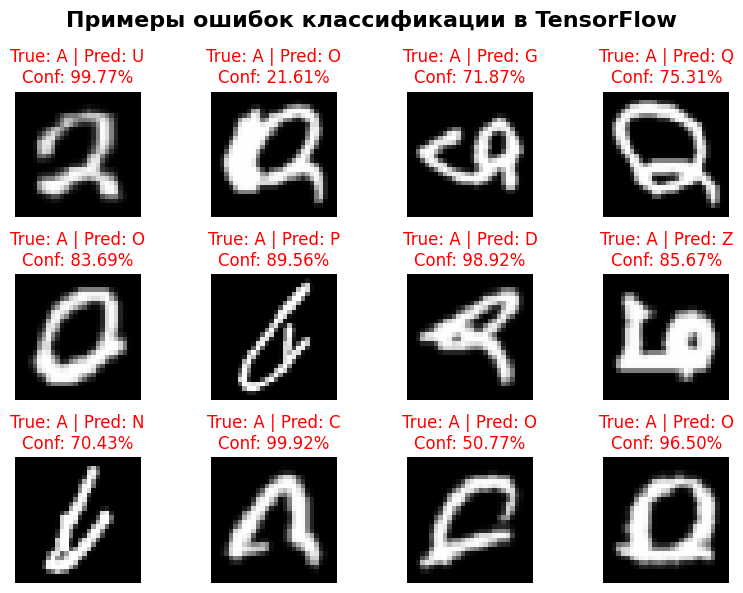

In [32]:
# Находим индексы всех ошибок
error_indices = np.where(tflow_preds != y_test)[0]

# Берем первые 12 ошибочных индексов
selected_errors = error_indices[:12]

# Отрисовка сетки 3x4
plt.figure(figsize=(8, 6))
for rank, idx in enumerate(selected_errors):
    plt.subplot(3, 4, rank + 1)

    # Отрисовываем картинку
    img = X_test[idx].reshape(28, 28)
    plt.imshow(img, cmap='gray')

    true_letter = labels_az[y_test[idx]]
    pred_letter = labels_az[tflow_preds[idx]]

    # Берем уверенность модели в своем ОШИБОЧНОМ ответе
    confidence = tflow_probs[idx, tflow_preds[idx]] * 100

    plt.title(f"True: {true_letter} | Pred: {pred_letter}\nConf: {confidence:.2f}%",
              color='red', fontsize=12)
    plt.axis('off')

plt.suptitle("Примеры ошибок классификации в TensorFlow", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()


### Сравнение ошибок двух фреймворков

1. Характер ошибок в обоих фреймворках совпадает на 80%. Четыре из пяти самых частых путаниц у моделей абсолютно одинаковы:

  - L и I: Главный тупик для обеих нейросетей. В рукописном вводе обе буквы пишутся как вертикальная линия (|).

  - Q и G: Вторая по частоте путаница. Если округлый хвост у Q или внутренний элемент у G написаны небрежно, модели не могут различить их на пиксельном уровне.

2. Все ошибки можно разделить по двум категориям:

  - Геометрическое сходство примитивов (Визуальная схожесть)

    Архитектура MLP не знает, что такое «линия» или «закругление». Она видит картинку как плоский вектор из пикселей. Если у двух разных букв (например, I и L) активные белые пиксели расположены на одних и тех же позициях, для математики слоев эти объекты становятся неотличимыми.

  - Человеческий фактор (Шум в данных)

    Рукописные буквы из датасета EMNIST содержат колоссальное количество небрежного написания. Буквы пишутся с разным наклоном, со смазанными элементами или деформациями (например, A, похожая на U без верхней перекладины, или G, написанная как Q).

3. Основные паттерны ошибок:

  - Ошибки моделей не случайны. Они строго сгруппированы в взаимно-путаемые пары букв со схожей геометрией (I/L, G/Q, J/I, D/O).

  - Буквы со сложной и уникальной структурой (M, W, P, T, O) обе модели распознают отлично — с точностью до 96–97.8%.

4. Меньше ошибок допустила модель PyTorch. Это подтверждается как итоговой тестовой точностью, так и суммарным количеством ошибок в самых проблемных зонах. Например, на самой сложной паре I и L модель PyTorch совершила на 16 ошибок меньше, чем TensorFlow.Разница в качестве минимальна, что доказывает: оба фреймворка успешно справились с математическим представлением архитектуры перцептрона.

## Инференс и демо

### Функция predict_letter

In [33]:
def predict_letter(
    image_path: str,
    model: Any,
    framework: Literal['pytorch', 'tensorflow'] = 'pytorch'
) -> Tuple[str, float]:

    framework = framework.lower()
    if framework not in ['pytorch', 'tensorflow']:
        raise ValueError(f"Неверный фреймворк '{framework}'. Допустимые значения: 'pytorch' или 'tensorflow'")
    # Загрузка изображения и перевод в grayscale
    img = Image.open(image_path).convert('L')

    # Изменение размера до 28x28 пикселей
    img = img.resize((28, 28))

    # Преобразование в NumPy-массив float32
    img_array = np.array(img, dtype=np.float32)

    # Инверсия цветов, если фон светлый (среднее > 127)
    if np.mean(img_array) > 127:
        img_array = 255.0 - img_array

    # Нормализация (масштабирование в диапазон [0.0, 1.0])
    img_array /= 255.0
    img_array = img_array.T

    # Изменение формы на (1, 784) для полносвязного слоя
    img_tensor = img_array.reshape(1, 784)

    alphabet = string.ascii_uppercase  # 'ABCDEFGHIJKLMNOPQRSTUVWXYZ'

    if framework == 'pytorch':
        # Перевод модели в режим eval
        model.eval()

        # Конвертация numpy-массива в тензор PyTorch
        # Пытаемся определить устройство (GPU/CPU), на котором находится модель
        device = next(model.parameters()).device
        tensor = torch.tensor(img_tensor, dtype=torch.float32).to(device)

        # Отключаем расчет градиентов для ускорения инференса
        with torch.no_grad():
            outputs = model(tensor)
            # Применение Softmax для получения вероятностей
            probabilities = torch.nn.functional.softmax(outputs, dim=1)

        # Извлечение максимальной уверенности и индекса класса
        conf, class_idx = torch.max(probabilities, dim=1)
        confidence = conf.item()
        predicted_idx = class_idx.item()

    elif framework == 'tensorflow':
        # Предсказание вероятностей
        predictions = model.predict(img_tensor, verbose=0)

        predicted_idx = int(np.argmax(predictions, axis=1)[0])
        confidence = float(predictions[0][predicted_idx])


    # Преобразование индекса в заглавную букву
    predicted_letter = alphabet[predicted_idx]

    return img, predicted_letter, confidence


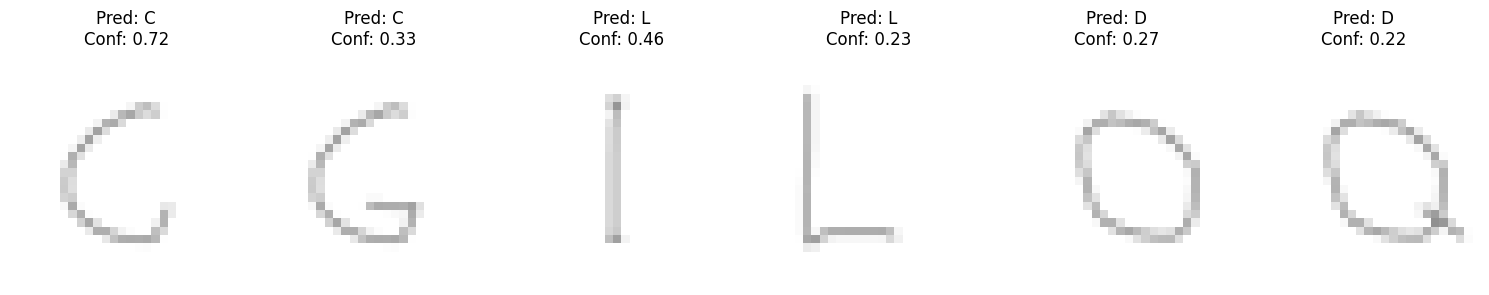

In [35]:
image_paths = [
    '/content/C.png',
    '/content/G.png',
    '/content/I.png',
    '/content/L.png',
    '/content/O.png',
    '/content/Q.png'
]

plt.figure(figsize=(15, 3))

for i, path in enumerate(image_paths):
  img, predicted_letter, confidence = predict_letter(
    image_path = path,
    model = model_torch_dropout,
    framework = 'pytorch'
  )

  plt.subplot(1, 6, i + 1)
  plt.imshow(img, cmap='gray', vmin=0, vmax=255)
  plt.title(f"Pred: {predicted_letter}\nConf: {confidence:.2f}")
  plt.axis('off')  # Отключаем оси координат

plt.tight_layout()
plt.show()

### Отчет о тестировании

1. Для проверки качества работы финальной модели были подготовлены 6, нарисованных в графическом редакторе, изображений английских букв: C, G, I, L, O, Q.

    Буквы были написаны чистом белом фоне, достаточно небрежно, плюс буквы G, L, Q были нарисованы из букв C, I, O просто добавлением "палочек". Что также добавляет сложности в распознавании.

 2. Была использована лучшая модель model_torch_dropout (PyTorch).

 3. Результаты:

  - C — Распознана верно с высокой уверенностью (Conf: 0.72).

  - G — Распознана неверно (Pred: C, однако модель колеблется, выдав низкую уверенность Conf: 0.33). Буква G вошла в топ-5 частых путаниц.

  - L — Распознана верно с низкой уверенностью (Conf: 0.23). Вероятно, могла быть перепутана с I.

  - I — Ошибочно распознана как L (Conf: 0.46). Ожидаемо, данная пара также вошла в топ-5 частых путаниц.

  - O и Q — Обе буквы ошибочно распознаны как D с уверенностью Conf: 0.27 и Conf: 0.22 соответственно. Неожиданна ошибка с буквой О, так как она вошла в топ-5 букв с лучшим распознаванием. По букве Q ожидаемо,  она вошла в топ-5 частых путаниц.

 4. Возможные причины ошибок:

    "Рукописные" примеры написаны слишком тонкими линиями. В датасете EMNIST буквы представляют собой жирные мазки (имитация жирного маркера или фломастера). При сжатии до разрешения 28x28 пикселей тонкие линии становятся размытыми и теряют ключевые фичи. В совокупности с тем, что были выбраны одни из наиболее сложных для распознавания букв, это привело к таким результатам.
  
5. В процессе выполнения проекта самым сложным было подготовить данные к обучению и настроить сам процесс обучения. На данном этапе не могу отдать предпочтения ни одному из фреймворков. Pytorch выглядил проще при подготовке к обучению, а также показал немного более высокий результат. Однако Tensorflow гораздо быстрее выполнил процесс обучения, что подкупает, так как создается впечатление, что он "правильнее" работает под капотом. Поэтому было бы очень интересно изучить глубже данные фреймворки, чтобы сформировать предпочтения.

    Если бы я делал данный проект заново, то постарался бы уделить больше времени изучению исходного датасета и подготовке данных для обучения. В таком случае, я думаю, было бы легче ориентироваться в результатах работы моделей, а также понимать причины верных или неверных предсказаний.